In [ ]:
%load_ext autoreload
%autoreload 2

import jax
jax.config.update("jax_enable_x64", True)

from mGST.low_level_jit import cost_function_jax_mps
from mGST.utility_functions_comparisons import GSTConfiguration, get_full_mgst_parameters_from_configuration, get_initial_gate_set_for_optimization
from mGST.trust_region import run_riemannian_optimization, are_all_tensors_in_gate_set_isometries
from mGST.typing import OperatorSchedule, TrustRegionOptions
from mGST.visualization import plot_cost_function

backend = "iqmfakeapollo"

/Users/emiliano.godinez/.pyenv/versions/qcvv-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [18]:
num_seq = 1974
num_qubits = 3
dim = 2 ** num_qubits
state_rank = dim
povm_rank = dim
kraus_rank = 4
num_shots = 1000

title_init = rf"{num_qubits}Q | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank} | Random Noisy Gate Set | Shots: {num_shots}"

In [3]:
config = GSTConfiguration(
    qubit_layouts=[[0,1,3]],
    gate_set="3QXYCZ",
    num_circuits=num_seq,
    shots=num_shots,
    rank=kraus_rank,
)

kraus_tensor_mgst, kraus_mgst, povm_mgst, state_mgst, prob_matrix, indices_list, additional_mgst_vars = get_full_mgst_parameters_from_configuration(
    config, backend, only_jax_variables=False
)

target_gate_set_superops = {
    "kraus": kraus_mgst,
    "povm": povm_mgst,
    "state": state_mgst
}

cost_fn_kwargs = {
    "indices_list": indices_list,
    "prob_matrix": prob_matrix,
    "jit": True,
    "use_log_likelihood": True,
    "verbose": False,  # we don't want to print during the cost function evaluation
    "num_shots": num_shots,
}

2026-10-27 08:45:04,411 - iqm.benchmarks.logging_config - INFO - Generating 1974 random GST circuits
2026-10-27 08:45:05,343 - iqm.benchmarks.logging_config - INFO - Will transpile all 1974 circuits according to fixed physical layout
2026-10-27 08:45:06,117 - iqm.benchmarks.logging_config - INFO - Transpiling for backend IQMFakeApolloBackend with optimization level 0, sabre routing method all circuits
2026-10-27 08:45:13,677 - iqm.benchmarks.logging_config - INFO - Submitting batch with 1974 circuits corresponding to qubits [0, 1, 3]
2026-10-27 08:45:13,688 - iqm.benchmarks.logging_config - INFO - Stored jobs for 1 layouts in dataset
2026-10-27 08:45:13,748 - iqm.benchmarks.logging_config - INFO - Now executing the corresponding circuit batch
2026-10-27 08:45:13,767 - iqm.benchmarks.logging_config - INFO - Retrieving all counts
2026-10-27 08:45:16,844 - iqm.benchmarks.logging_config - INFO - Adding counts to dataset
2026-10-27 08:45:25,768 - iqm.benchmarks.logging_config - INFO - Run c

In [4]:
spam_depolarization = 1e-2

init_gate_set_psd_interior = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    # the rank-4 truncation of the perturbed (full-rank) channel leaves |sum K^†K - I| ~ 5e-6
    project_kraus_to_isometry=True,
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_interior))

All isometries: True


In [10]:
num_iterations_outer = 20
num_iterations_tr = 5
num_iterations_cg = 10 
tol_grad = 1e-8 # it was 1e-4 before. 1e-8 is suggested in the book.
relative_precision = 1e-3 # changed due to the changes in convergence criteria
global_gradient_norm_tol = 1e-10

tr_options_distance = TrustRegionOptions(num_iterations=num_iterations_tr, verbose=True, verbose_cg=False, num_iterations_cg=num_iterations_cg, tol_grad=tol_grad, radius_heuristic="typical_distance")

schedule_distance = OperatorSchedule.default(num_iterations_outer, tr_options_distance)

optimization_schedule = {op: schedule_distance for op in ["povm", "kraus", "state"]}

optimization_options = {
    "optimization_schedule": optimization_schedule,
    "num_iterations": num_iterations_outer,
    "relative_precision": relative_precision, 
    "global_gradient_norm_tol": global_gradient_norm_tol,
    "noise_threshold": None,
    "compute_least_squares": 1,
    "carry_over_radius": True,
    "absolute_tolerance": 1, # for the log likelihood convergence
    "verbose": True,
}

In [7]:
# Same options as the baseline run above, only the initial POVM and state differ.
optimized_operators_jax, cost_fn_history_jax, convergence_reason_jax = run_riemannian_optimization(
    *init_gate_set_psd_interior.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 3.150990e+06
 * jitted objective: yes (prefix contraction)
👾 Least squares value after POVM: 6.023331e-04 👾
👾 Least squares value after Kraus: 1.104878e-04 👾
👾 Least squares value after State at iteration 1: 1.076774e-04 👾
🏁 Iteration: 1/20. f(x): 3.158406e+06.

 🎯 Relative change in reducible cost over iteration 1: 9.35e-01. Target: 1.00e-03.
 📉 Decrease over iteration 1: 1.06e+05. Estimated remaining decrease: inf. Target: 1.00e+00.
👾 Least squares value after POVM: 9.395283e-05 👾
👾 Least squares value after Kraus: 8.633841e-05 👾
👾 Least squares value af

In [11]:
init_gate_set_psd_rank_16 = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=16,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True,
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_rank_16))

All isometries: True


In [12]:
optimized_operators_rank_16, cost_fn_history_rank_16, convergence_reason_rank_16 = run_riemannian_optimization(
    *init_gate_set_psd_rank_16.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 3.150990e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (typical_distance heuristic): Δ0 = 3.54e-01. Δmax = 2.83e+00
TR Iteration: 0. f(x): 3.255360e+06. |r∇f(x)|: 1.363251e+05. Radius: 3.54e-01
TR Iteration: 1. f(x): 3.209952e+06. |r∇f(x)|: 1.084097e+05. Radius: 3.54e-01
TR Iteration: 2. f(x): 3.184156e+06. |r∇f(x)|: 6.140579e+04. Radius: 7.07e-01
TR Iteration: 3. f(x): 3.176007e+06. |r∇f(x)|: 6.694385e+04. Radius: 7.07e-01
TR Iteration: 4. f(x): 3.168076e+06. |r∇f(x)|: 8.267388e+03. Radius: 7.07e-01
Optimizatio

In [14]:
init_gate_set_psd_rank_1 = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=1,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True,
)

print("All isometries:", are_all_tensors_in_gate_set_isometries(init_gate_set_psd_rank_1))

All isometries: True


In [15]:
optimized_operators_rank_1, cost_fn_history_rank_1, convergence_reason_rank_1 = run_riemannian_optimization(
    *init_gate_set_psd_rank_1.values(),
    cost_function=cost_function_jax_mps,
    cost_fn_kwargs=cost_fn_kwargs,
    **optimization_options,
)

⚠️ Computing least squares values during optimization. This may add additional computational overhead. ⚠️
🔰 Starting Riemannian Optimization 🔰
 * optimization schedule: 
povm: Schedule:
  [0-19]: TrustRegionOptions
kraus: Schedule:
  [0-19]: TrustRegionOptions
state: Schedule:
  [0-19]: TrustRegionOptions 
* Convergence Criteria: 
+ Relative Precision 📏 1.00e-03 
+ Absolute Tolerance 📉 1.00e+00 
+ Gradient(s) Norm(s) 📐
 * cost floor: 3.150990e+06
 * jitted objective: yes (prefix contraction)
🚀 TR started for operator: povm 🚀.
Radii (typical_distance heuristic): Δ0 = 3.54e-01. Δmax = 2.83e+00
TR Iteration: 0. f(x): 3.345528e+06. |r∇f(x)|: 2.127098e+05. Radius: 3.54e-01
TR Iteration: 1. f(x): 3.280076e+06. |r∇f(x)|: 1.584928e+05. Radius: 7.07e-01
TR Iteration: 2. f(x): 3.237971e+06. |r∇f(x)|: 1.222398e+05. Radius: 7.07e-01
TR Iteration: 3. f(x): 3.218568e+06. |r∇f(x)|: 6.958897e+04. Radius: 7.07e-01
TR Iteration: 4. f(x): 3.211235e+06. |r∇f(x)|: 7.461952e+03. Radius: 7.07e-01
Optimizatio

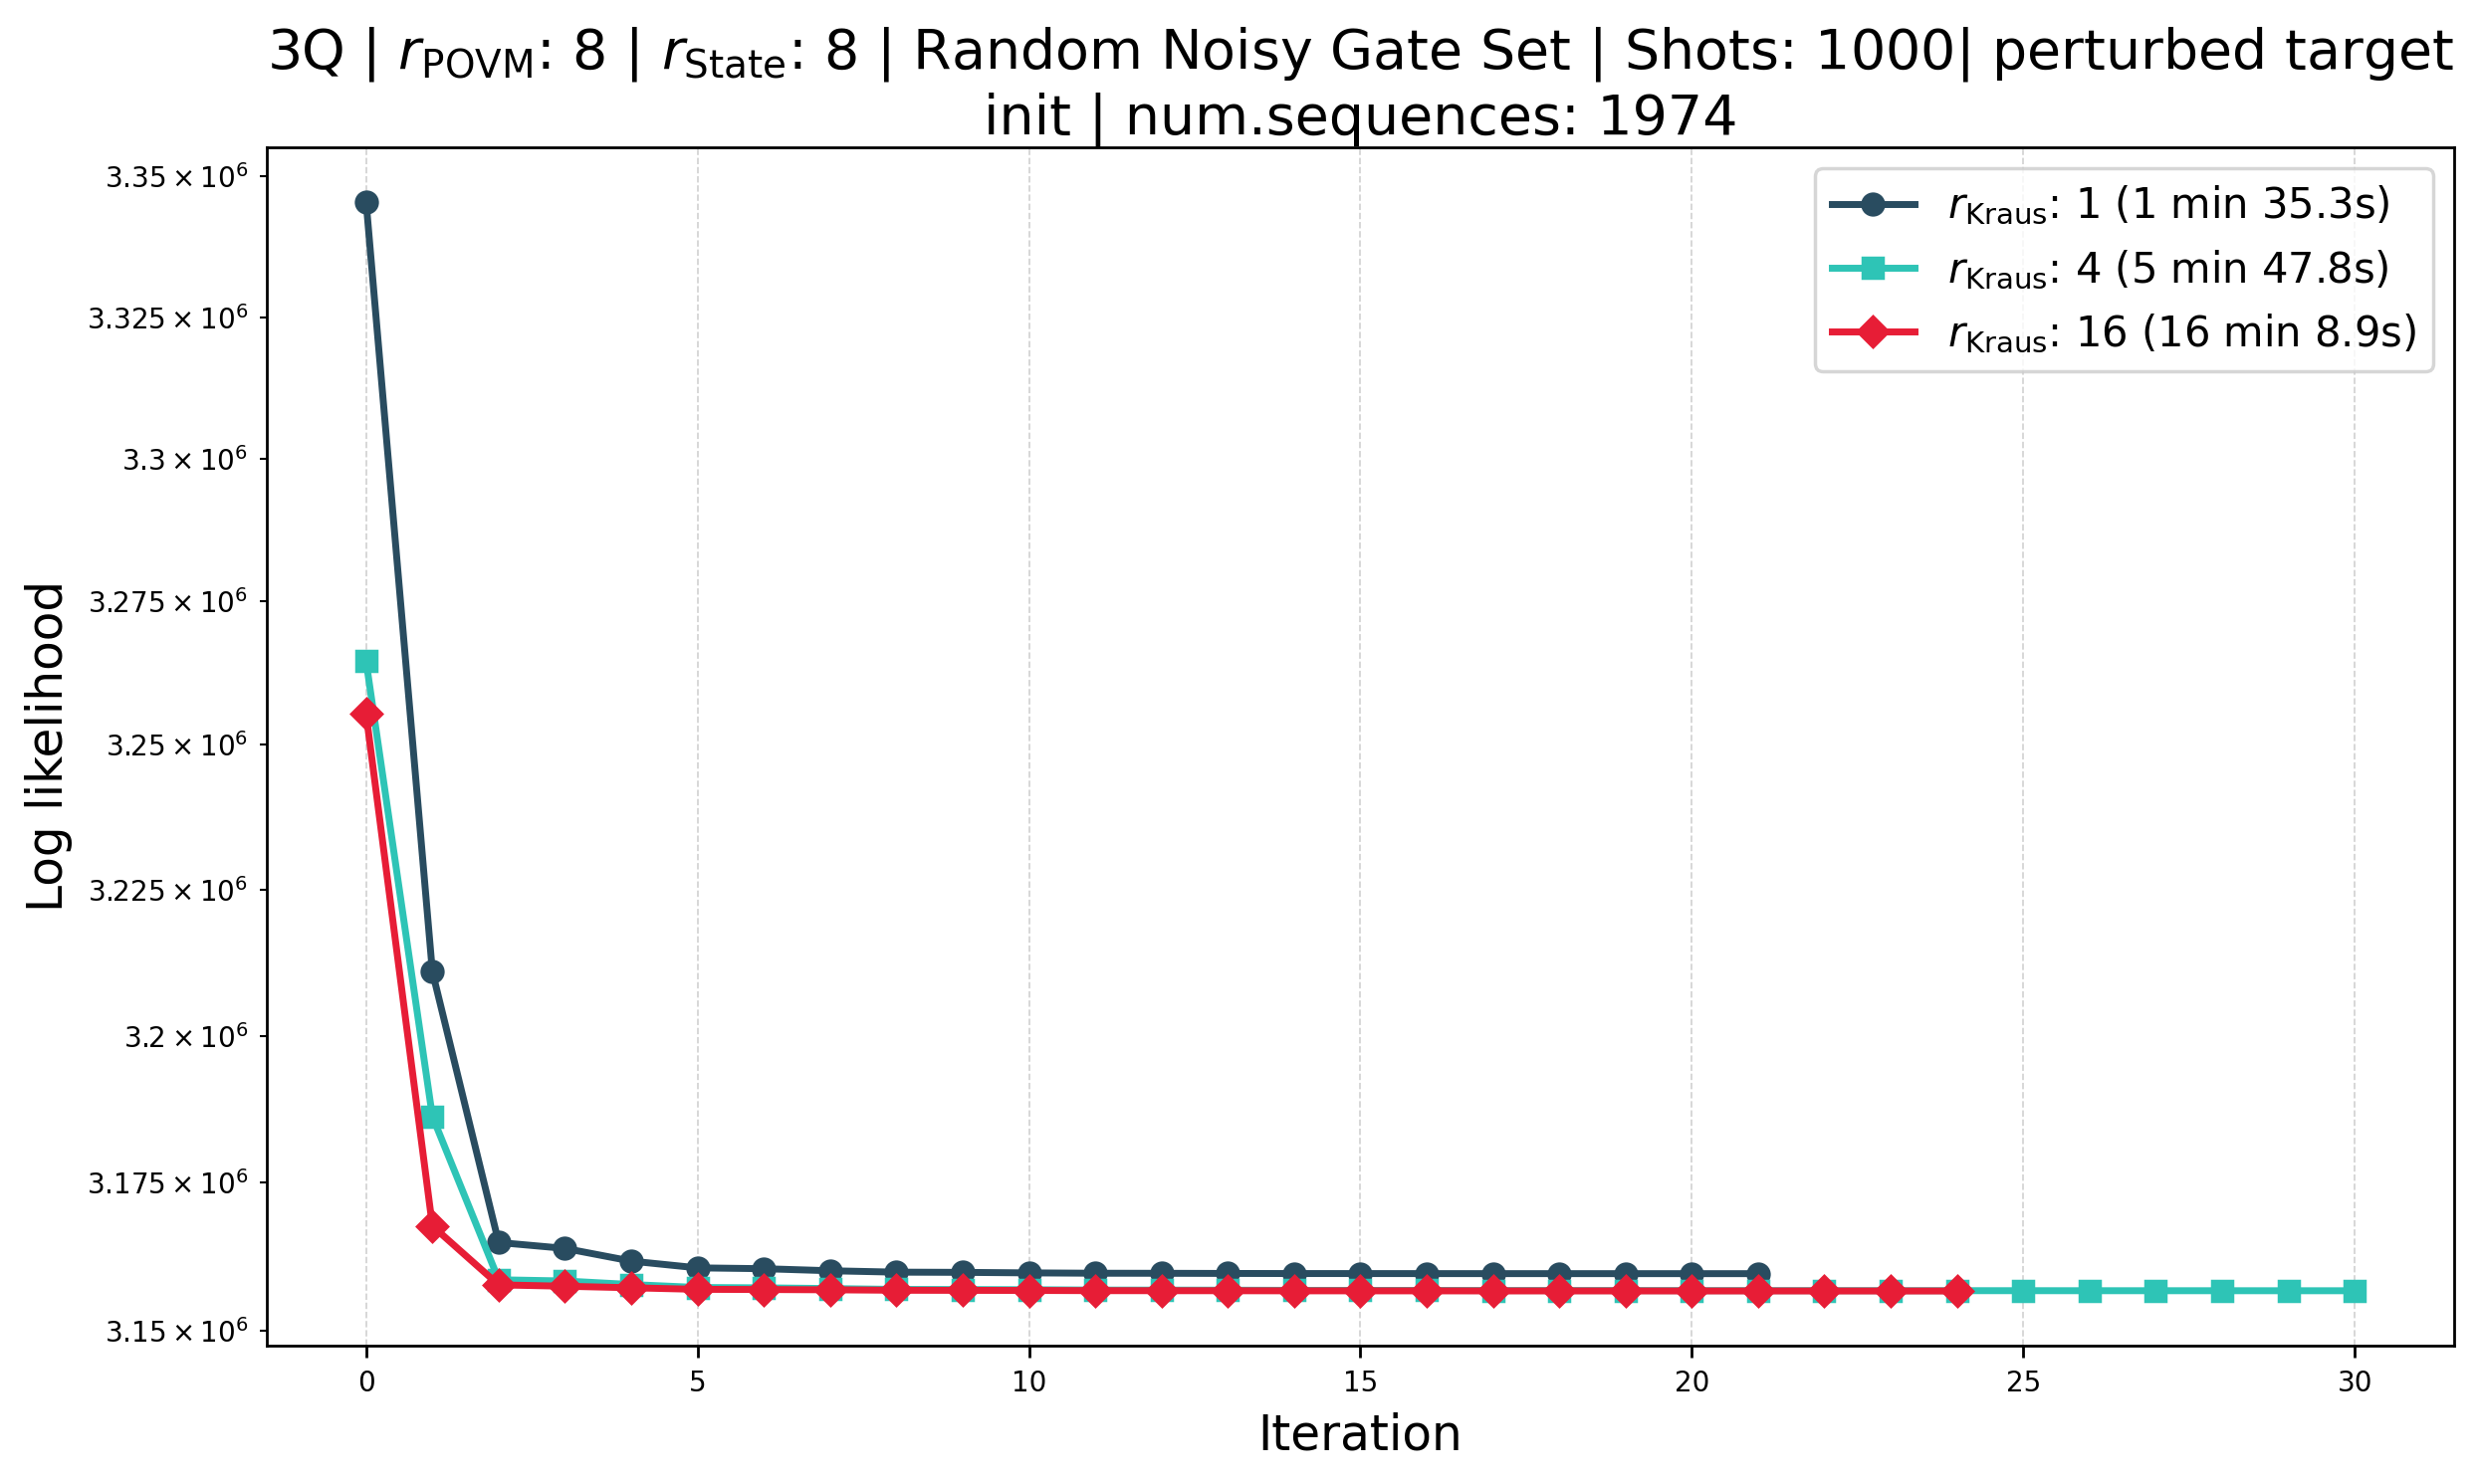

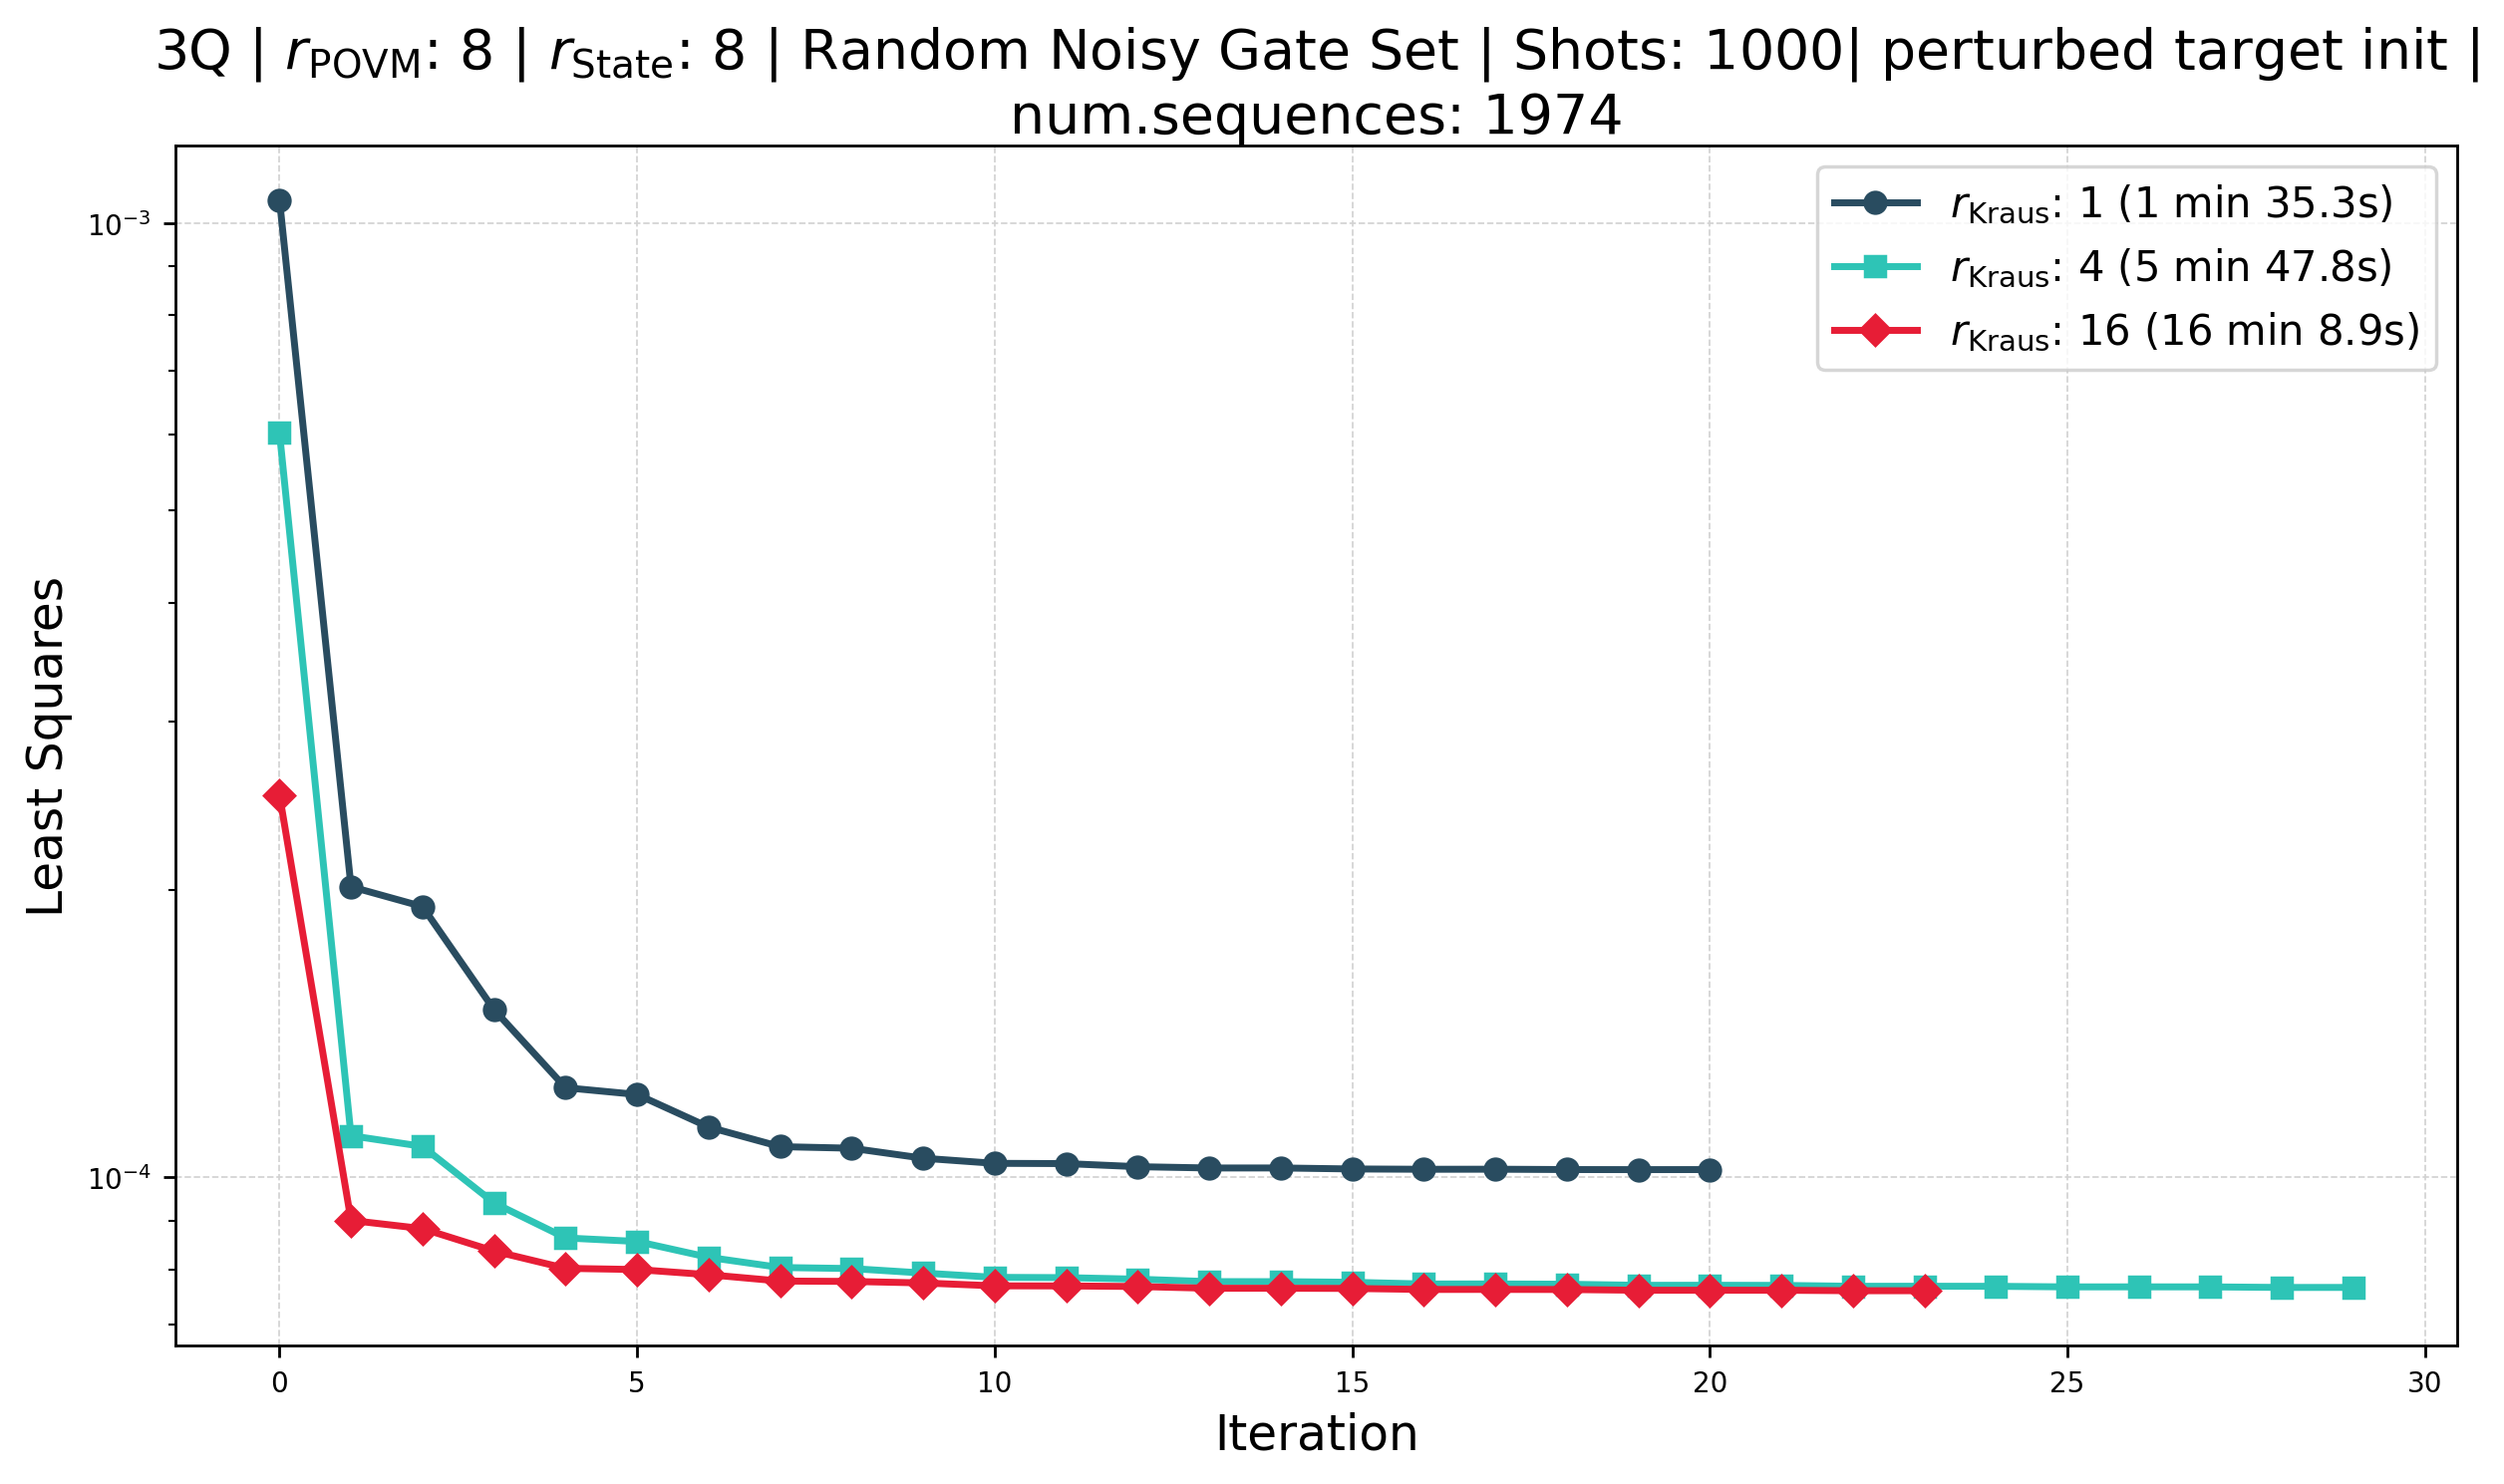

In [20]:
labels = [rf"$r_\mathrm{{Kraus}}$: 1 (1 min 35.3s)", rf"$r_\mathrm{{Kraus}}$: 4 (5 min 47.8s)", rf"$r_\mathrm{{Kraus}}$: 16 (16 min 8.9s)"]

title_comparison = title_init + f"| perturbed target init | num.sequences: {num_seq}"

cost_fns = [cost_fn_history_rank_1, cost_fn_history_jax, cost_fn_history_rank_16]
cost_loglikelihoods = [cost["main"] for cost in cost_fns]
cost_least_squares = [cost["least_squares"] for cost in cost_fns]

plot_cost_function(cost_loglikelihoods, title=title_comparison, labels=labels, ylabel="Log likelihood")

plot_cost_function(cost_least_squares, title=title_comparison, labels=labels, ylabel="Least Squares")